# Check numerical resolution in a Fe-Cr-Ni simulation

How much does the one-hour result change when we refine the phase grids, time
steps, or bulk sampling? We vary one control at a time. The finest run is a
comparison reference, not an exact solution; decreasing differences are not guaranteed.

Run cells from top to bottom in the `kawin` environment with the package installed.
Start the kernel in this examples directory or at the extraction repository root.
Each notebook is independent; no earlier notebook needs to have been run.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt

from moving_boundary.mesh import CartesianFD1D, ProfileBuilder, StepProfile1D
from moving_boundary.mesh.TransformedGrids import two_phase_landau_grids
from moving_boundary.plotting import plot_composition_profiles, plot_interface_history
from moving_boundary.providers.pycalphad import create_pycalphad_thermodynamics_source
from moving_boundary.sampling import ternary_simplex_points
from moving_boundary.solvers import MovingBoundaryIllingworthTernaryFD1DModel
from moving_boundary.surrogates import TernaryMovingBoundaryThermodynamicsSurrogate
import numpy as np

## Define the couple

These are the introductory notebook's couple B inputs [1, 2]. Phases run left to
right; FE is dependent and composition pairs are `[X_CR, X_NI]` mole fractions.
Units are metres, seconds and kelvin. We model half of a symmetric FCC/BCC/FCC
couple with zero-flux outer boundaries, equal constant molar volumes and no bulk flow.
The interface has local equilibrium. The tiny position offset avoids a mesh node.

The adapted open MatCalc database [3, 4] is bundled beside these notebooks;
[the README](README.md#open-fe-cr-ni-database-and-surrogate-workflow) documents
its attribution and licence. Edit `database` if using another file location.

In [ ]:
#NOTES I think the above text should mention that this is the same database/setup as the other examples which use it
database = Path("FeCrNi_MatCalc_open.tdb")  # kernel starts beside this notebook
if not database.is_file():
    database = Path("packages/moving-boundary/examples") / database  # repository root

elements = ["FE", "CR", "NI"]
independent = ["CR", "NI"]
phases = ["BCC_A2", "FCC_A1"]
temperature = 1373.0
left_composition = [0.39696, 0.0001]   # BCC far field [2, Table 3]
right_composition = [0.139297, 0.142387]  # FCC far field [2, Table 3]

domain_length = 2000.0e-6 + 124.1e-6 / 2.0
interface_position = domain_length - 2000.0e-6 + 1.0e-12
duration = 3600.0

## Sample the open database

Restrict equilibrium to BCC_A2 and FCC_A1. The interior probe seeds a family
of 17 tie lines; it is not the initial bulk composition. The bulk grid has
spacing 0.05. Unusable bulk matrices are omitted, and `validity_policy="raise"`
rejects unsupported queries. These demonstration settings are not converged.
This cell samples afresh; progress output is collapsed in the saved notebook.

In [3]:
source = create_pycalphad_thermodynamics_source(
    database, elements, phases, use_default_phases=False, g_offset=0.0,
)

bulk_points = ternary_simplex_points(spacing=0.05)
surrogate = TernaryMovingBoundaryThermodynamicsSurrogate.from_database(
    thermodynamics=source,
    elements=elements,
    phases=phases,
    tieline_phases=phases,
    temperature=temperature,
    probe_point=[0.45, 0.21],
    probe_samples_per_side=8,
    precipitate_phase=phases[1],
    diffusivity_bulk_points=bulk_points,
    diffusivity_interpolation="simplex_positive_2x2",
    skip_failed_bulk_calculations=True,
    drop_invalid_bulk_matrices=True,
    validity_policy="raise",
    min_composition=1.0e-10,
)

for phase in phases:
    compositions, matrices = surrogate.get_diffusivity_samples(phase)
    print(f"{phase}: {len(compositions)} retained bulk diffusivity samples")

Initial scan direction: [0.59321673 0.8050428 ]
Initial seed_sample: {'probe': array([0.45, 0.21]), 'endpoints': (array([0.57577713, 0.11731785]), array([0.35589239, 0.27934564])), 'diffusivities': (array([[1.51312606e-13, 1.69738852e-13],
       [3.93063828e-14, 9.29449039e-14]]), array([[ 3.83127736e-15, -1.42282854e-15],
       [-9.43938713e-16,  4.74858267e-15]])), 'midpoint': array([0.46583476, 0.19833174])}
totalNumCalcs: -1


i+1: 32
j: 14
scan direction after neg scan: [0.59321673 0.8050428 ]
seed_sample after neg scan: {'probe': array([0.45, 0.21]), 'endpoints': (array([0.57577713, 0.11731785]), array([0.35589239, 0.27934564])), 'diffusivities': (array([[1.51312606e-13, 1.69738852e-13],
       [3.93063828e-14, 9.29449039e-14]]), array([[ 3.83127736e-15, -1.42282854e-15],
       [-9.43938713e-16,  4.74858267e-15]])), 'midpoint': array([0.46583476, 0.19833174])}
totalNumCalcs: -1


i+1: 24
j: 14
scan direction after pos scan: [0.59321673 0.8050428 ]
seed_sample after pos scan: {

Resampling tieline data: 100%|██████████| 17/17 [00:00<00:00, 45.39it/s]


totalNumCalcs: -1


Sampling bulk diffusivity for phase FCC_A1: 100%|██████████| 231/231 [00:01<00:00, 167.10it/s]


BCC_A2: 248 retained bulk diffusivity samples
FCC_A1: 248 retained bulk diffusivity samples


## Define the repeated model construction

Every solve needs a fresh mesh and model. This small factory exposes only the
controls varied below. The physical 61-point mesh, physical inputs, tie-line
family, interpolation and initial-interface settings stay unchanged.

In [4]:
def make_model(surrogate, *, left_nodes=21, right_nodes=41, semi_log_dt=0.05):
    """Build the same closed couple with independently adjustable phase grids and time steps."""
    mesh = CartesianFD1D(independent, [0.0, domain_length], 61)
    profile = ProfileBuilder([
        (StepProfile1D(interface_position, left_composition, right_composition), independent)
    ])
    mesh.setResponseProfile(profile)

    left_grid, right_grid = two_phase_landau_grids(
        left_nodes, right_nodes, method="linear", spacing_ratio=0.1,
    )
    return MovingBoundaryIllingworthTernaryFD1DModel(
        mesh=mesh,
        elements=elements,
        phases=phases,
        thermodynamics=surrogate,
        temperature=temperature,
        interfacePosition=interface_position,
        interface_equilibrium=surrogate,
        initial_eta_method="instantaneous_balance",
        initial_eta_bracket=(1.0e-3, 1.0 - 1.0e-3),
        initial_eta_guess=0.5,
        bulk_diffusivity_mode="composition_dependent_lagged",
        transformed_u_grid=left_grid,
        transformed_v_grid=right_grid,
        time_step=1.0,
        dt_mode="semi_log",
        semiLog_dt=semi_log_dt,
        semiLogT0=1.0e-6,
        tolerance=1.0e-12,
        terminal_thin_phase_width=1.0e-7,
        terminal_thin_phase_policy="raise",
        record=True,
    )

## Refine the transformed grids

Keep the surrogate and semi-logarithmic increment 0.05 fixed. These node counts
affect the phase solves, not the physical mesh used to supply the initial profile.

In [5]:
spatial_models = []
for counts in ((21, 41), (41, 81), (81, 161)):
    candidate = make_model(surrogate, left_nodes=counts[0], right_nodes=counts[1])
    candidate.solve(duration, minDtFrac=1.0e-14)
    spatial_models.append((str(counts), candidate))
    print("Completed phase grids", counts)

Completed phase grids (21, 41)
Completed phase grids (41, 81)
Completed phase grids (81, 161)


## Refine the time schedule

Keep the original 21/41 phase grids and surrogate fixed. `semiLog_dt` controls
logarithmic time spacing; the solver may still retry a candidate step.

In [6]:
temporal_models = []
for increment in (0.05, 0.025, 0.0125):
    candidate = make_model(surrogate, semi_log_dt=increment)
    candidate.solve(duration, minDtFrac=1.0e-14)
    temporal_models.append((str(increment), candidate))
    print("Completed semiLog_dt", increment)

Completed semiLog_dt 0.05
Completed semiLog_dt 0.025
Completed semiLog_dt 0.0125


## Refine bulk sampling

Keep the 21/41 grids, time increment 0.05, and 17-tie-line family fixed. Change
only the requested bulk composition spacing; rebuild the surrogate when it changes.
This probes bulk interpolation sensitivity, not tie-line resolution or database accuracy.

In [7]:
sampling_models = []
for spacing in (0.10, 0.05, 0.025):
    if spacing == 0.05:
        sampled = surrogate
    else:
        sampled = TernaryMovingBoundaryThermodynamicsSurrogate.from_database(
            thermodynamics=source, elements=elements, phases=phases, tieline_phases=phases,
            temperature=temperature, probe_point=[0.45, 0.21], probe_samples_per_side=8,
            precipitate_phase=phases[1], diffusivity_bulk_points=ternary_simplex_points(spacing=spacing),
            diffusivity_interpolation="simplex_positive_2x2", skip_failed_bulk_calculations=True,
            drop_invalid_bulk_matrices=True, validity_policy="raise", min_composition=1.0e-10,
        )
    candidate = make_model(sampled)
    candidate.solve(duration, minDtFrac=1.0e-14)
    sampling_models.append((str(spacing), candidate))
    print("Completed bulk spacing", spacing)

Initial scan direction: [0.59321673 0.8050428 ]
Initial seed_sample: {'probe': array([0.45, 0.21]), 'endpoints': (array([0.57577713, 0.11731785]), array([0.35589239, 0.27934564])), 'diffusivities': (array([[1.51312606e-13, 1.69738852e-13],
       [3.93063828e-14, 9.29449039e-14]]), array([[ 3.83127736e-15, -1.42282854e-15],
       [-9.43938713e-16,  4.74858267e-15]])), 'midpoint': array([0.46583476, 0.19833174])}
totalNumCalcs: -1


i+1: 32
j: 14
scan direction after neg scan: [0.59321673 0.8050428 ]
seed_sample after neg scan: {'probe': array([0.45, 0.21]), 'endpoints': (array([0.57577713, 0.11731785]), array([0.35589239, 0.27934564])), 'diffusivities': (array([[1.51312606e-13, 1.69738852e-13],
       [3.93063828e-14, 9.29449039e-14]]), array([[ 3.83127736e-15, -1.42282854e-15],
       [-9.43938713e-16,  4.74858267e-15]])), 'midpoint': array([0.46583476, 0.19833174])}
totalNumCalcs: -1


i+1: 24
j: 14
scan direction after pos scan: [0.59321673 0.8050428 ]
seed_sample after pos scan: {

Resampling tieline data: 100%|██████████| 17/17 [00:00<00:00, 53.03it/s]


totalNumCalcs: -1


Sampling bulk diffusivity for phase FCC_A1: 100%|██████████| 66/66 [00:00<00:00, 203.05it/s]


Completed bulk spacing 0.1
Completed bulk spacing 0.05
Initial scan direction: [0.59321673 0.8050428 ]
Initial seed_sample: {'probe': array([0.45, 0.21]), 'endpoints': (array([0.57577713, 0.11731785]), array([0.35589239, 0.27934564])), 'diffusivities': (array([[1.51312606e-13, 1.69738852e-13],
       [3.93063828e-14, 9.29449039e-14]]), array([[ 3.83127736e-15, -1.42282854e-15],
       [-9.43938713e-16,  4.74858267e-15]])), 'midpoint': array([0.46583476, 0.19833174])}
totalNumCalcs: -1


i+1: 32
j: 14
scan direction after neg scan: [0.59321673 0.8050428 ]
seed_sample after neg scan: {'probe': array([0.45, 0.21]), 'endpoints': (array([0.57577713, 0.11731785]), array([0.35589239, 0.27934564])), 'diffusivities': (array([[1.51312606e-13, 1.69738852e-13],
       [3.93063828e-14, 9.29449039e-14]]), array([[ 3.83127736e-15, -1.42282854e-15],
       [-9.43938713e-16,  4.74858267e-15]])), 'midpoint': array([0.46583476, 0.19833174])}
totalNumCalcs: -1


i+1: 24
j: 14
scan direction after pos scan

Resampling tieline data: 100%|██████████| 17/17 [00:00<00:00, 52.90it/s]


totalNumCalcs: -1


Sampling bulk diffusivity for phase FCC_A1: 100%|██████████| 861/861 [00:03<00:00, 229.62it/s]


Completed bulk spacing 0.025


## Compare final positions and profiles

Each row reports displacement relative to the finest run **within that study**.
The three studies have different reference configurations. Profiles are plotted
separately by phase so no interpolation crosses the composition jump. We show
chromium near the interface for clarity; use `elements=["NI"]` to inspect nickel.

Phase grids: setting, final position (μm), difference from finest (μm)
(21, 41)     72.054135 +0.124160
(41, 81)     71.968818 +0.038843
(81, 161)    71.929975 +0.000000
Time increment: setting, final position (μm), difference from finest (μm)
0.05         72.054135 -0.040894
0.025        72.081355 -0.013674
0.0125       72.095030 +0.000000
Bulk spacing: setting, final position (μm), difference from finest (μm)
0.1          72.041735 -0.129074
0.05         72.054135 -0.116674
0.025        72.170809 +0.000000


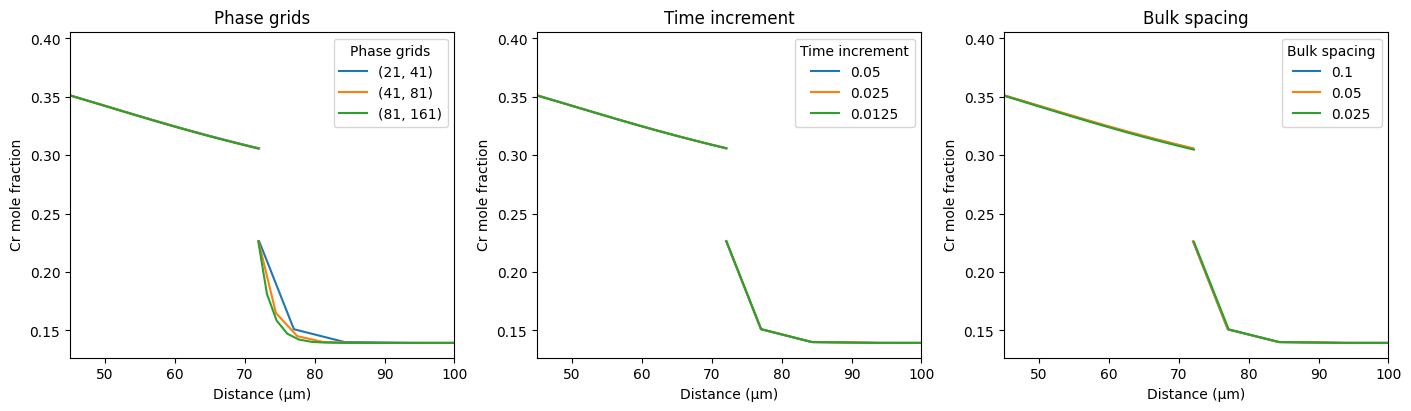

In [9]:
studies = {"Phase grids": spatial_models, "Time increment": temporal_models, "Bulk spacing": sampling_models}
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for ax, (name, runs) in zip(axes, studies.items()):
    reference = float(runs[-1][1].getInterfacePosition())
    print(f"{name}: setting, final position (μm), difference from finest (μm)")
    for index, (label, candidate) in enumerate(runs):
        position = float(candidate.getInterfacePosition())
        print(f"{label:12s} {position * 1e6:.6f} {(position - reference) * 1e6:+.6f}")
        plot_composition_profiles(candidate, elements=["CR"], ax=ax, position_scale=1.0e6,
                                  color=f"C{index}", label=label)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::2], labels[::2], title=name)
    ax.set(title=name, xlim=(45, 100), xlabel="Distance (μm)", ylabel="Cr mole fraction")
plt.show()

## Interpretation

Choose acceptable changes for your scientific question and continue refining if
necessary. This finite-domain comparison does not establish experimental accuracy,
tie-line convergence, or independence from the outer walls. Test domain size in a
separate study, keeping the near-interface resolution comparable.

## References

1. M. Kajihara, C.-B. Lim, M. Kikuchi, "Experimental study on dissolution of alpha
   phase in gamma/alpha/gamma diffusion couples of the Fe-Cr-Ni system,"
   *ISIJ International* 33 (1993) 498-507. Source of the couples and annealing temperature.
2. B.-J. Lee, K. H. Oh, "Numerical treatment of the moving interface in diffusional
   reactions," *Z. Metallkd.* 87 (1996) 195-204. Couple B compositions and dimensions
   from Table 3, originating in [1].
3. E. Povoden-Karadeniz, MatCalc thermodynamic steel database mc_fe, release 2.060,
   TU Wien, [MatCalc open databases](https://www.matcalc.at/index.php/databases/open-databases).
   Thermodynamic parameters in the bundled adapted excerpt; ODbL 1.0 / DbCL 1.0.
4. E. Povoden-Karadeniz, MatCalc diffusion mobility database for steel (mc_fe), TU Wien,
   same source and licence as [3]. Mobility parameters in the excerpt match releases
   2.012, 2.015, and 2.016; no single release is identified.